# Praktikum 3 - Naive Bayes Data Multinomial

**Nama:** Agus  
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js09-klasifikasi/praktikum-3)

Kode utama di bawah mengikuti blok kode dan urutan modul. Penyesuaian terbatas pada lokasi dataset, kompatibilitas API, dan perbaikan error. Analisis tambahan ditempatkan setelah seluruh langkah modul.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
np.random.seed(42)
print("Kernel:", sys.executable)

Kernel: /Volumes/External/miniconda3/envs/ml-praktikum/bin/python


## Langkah 1 - Load Data

In [2]:
import numpy as np
import pandas as pd

df = pd.read_csv('data/spam.csv', encoding='latin-1') # spesifiksi encoding diperlukan karena data tidak menggunakan UTF-8

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


## Langkah 2a - Drop Kolom

In [3]:
# Drop 3 kolom terakhir dengan fungsi iloc
df = df.drop(df.iloc[:,2:], axis=1)

# Cek data
df.head()

# Nama kolom dijelaskan di modul, tetapi baris rename terlewat pada contoh.
df = df.rename(columns={'v1': 'Labels', 'v2': 'SMS'})
df.head()

,Labels,SMS
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## Langkah 2b - Inspeksi Data

In [4]:
# Cek Jumlah Data Per Kelas
print(df['Labels'].value_counts())
print('\n')

# Cek Kelengkapan Data
print(df.info())
print('\n')

# Cek Statistik Deskriptif
print(df.describe())

Labels
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Labels  5572 non-null   str  
 1   SMS     5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB
None


       Labels                     SMS
count    5572                    5572
unique      2                    5169
top       ham  Sorry, I'll call later
freq     4825                      30


## Langkah 2c - Encoding Label

In [5]:
# Data untuk label
new_labels = {
    'spam': 1,
    'ham': 0
}

# Encode label
df['Labels'] = df['Labels'].map(new_labels)

# Cek data
df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


## Langkah 2d - Pisahkan Fitur dengan Label

In [6]:
X = df['SMS'].values
y = df['Labels'].values

## Langkah 3 - Ekstraksi Fitur

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

# Inisiasi CountVectorizer
bow = CountVectorizer()

# Fitting dan transform X_train dengan CountVectorizer
X_train = bow.fit_transform(X_train)

# Transform X_test
# Mengapa hanya transform? Alasan yang sama dengan kasus pada percobaan ke-3
# Kita tidak menginginkan model mengetahui paramter yang digunakan oleh CountVectorizer untuk fitting data X_train
# Sehingga, data testing dapat tetap menjadi data yang asing bagi model nantinya
X_test = bow.transform(X_test)

In [8]:
print(len(bow.get_feature_names_out()))
print(f'Dimensi data: {X_train.shape}')

7727
Dimensi data: (4457, 7727)


## Langkah 4 - Training dan Evaluasi Model

In [9]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Inisiasi MultinomialNB
mnb = MultinomialNB()

# Fit model
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_pred_train = mnb.predict(X_train)

# Evaluasi akurasi data training
acc_train = accuracy_score(y_train, y_pred_train)

# Prediksi dengan data training
y_pred_test = mnb.predict(X_test)

# Evaluasi akurasi data training
acc_test = accuracy_score(y_test, y_pred_test)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229


## Evaluasi dan analisis tambahan

              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       954
        spam       0.98      0.86      0.92       161

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



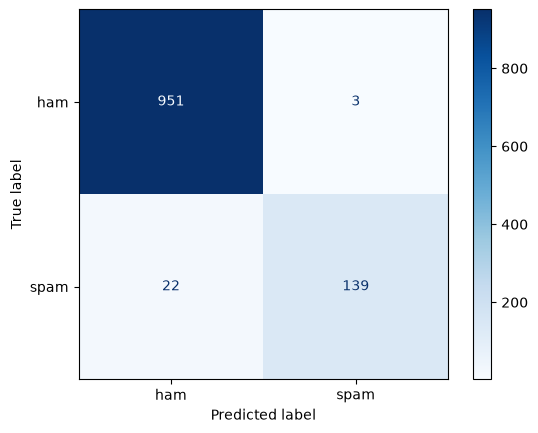

Teks berulang pada data asli: 403


In [10]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
print(classification_report(y_test, y_pred_test, target_names=['ham', 'spam'], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, display_labels=['ham', 'spam'], cmap='Blues')
plt.show()
print('Teks berulang pada data asli:', df['SMS'].duplicated().sum())

Kode utama mempertahankan seluruh data dan split seed 50 seperti modul. Vocabulary dipelajari hanya dari training. Data asli memuat teks berulang sehingga skor ini dapat terpengaruh SMS identik di kedua split. Pada tugas perbandingan fitur, duplikasi dan konflik label dibersihkan sebelum split.